# Assignment 7: Classification Analysis | Pair Assignment

**Goal:** build and compare a **Decision Tree** and a **Naive Bayes** classifier on your
group's dataset, then report what you found. EAch pair will choose one dataset from the following table and do the following.


Hints are provided in the cells marked `# TODO`. If you get stuck on syntax, check the code examples form this week.

> **Replace the loan_sample.cs with your chosen Kaggle dataset** and update the target column.

## Your dataset

| Group dataset | Example classification task | Target column | Kaggle link |
|---|---|---|---|
| SF Crime | Predict crime category, or district | `Category` / `PdDistrict` | https://www.kaggle.com/competitions/sf-crime/data
| NASA Asteroids | Predict if an asteroid is hazardous | `Hazardous` | https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
| Hotel Booking | Predict if a booking is cancelled, or hotel type | `is_canceled` / `hotel` | https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Use a Decision Tree for one task and Naive Bayes for the other (or, for Asteroids, run
both on the same task and compare). Keep notes as you go; you will need them for the report
at the bottom.

## Know your dataset before you start | Each pair will choose one of the following dataset

Read the block for your group's dataset first. It tells you what you are actually
predicting and the specific things to watch for at each step, so you are not surprised
halfway through.

### SF Crime, predicting crime category or district

**What you are figuring out:** can the time and place of an incident predict what kind of
crime it was, or which police district it happened in? You are turning raw incident logs
into useful predictors.

- **Exploration:** this file is huge (about 1 million rows). Take a random sample (say 50,000 rows) so your code runs fast. Check how many distinct crime categories exist.
- **Preprocessing:** the timestamp is not useful as text. Pull `hour`, `day of week`, and `month` out of it into their own numeric columns. If there are too many crime categories, group the rare ones into an "Other" bucket so the model is not splitting on dozens of tiny classes. Keep latitude and longitude; they are strong predictors.
- **Build models:** Decision Tree for one task (for example, category) and Naive Bayes for the other (district).
- **Evaluate:** with many classes, accuracy alone is thin. Look at the confusion matrix to see which categories get mixed up.

### NASA Asteroids, predicting hazardous (yes / no)

**What you are figuring out:** from an asteroid's size and orbital measurements, can you
predict whether NASA flags it as hazardous? This is the cleanest Decision Tree versus
Naive Bayes comparison of the three.

- **Exploration:** check the class balance first. Only about 16% are hazardous, so a model that always guesses "not hazardous" is already about 84% accurate. That is the baseline you must beat, and it is why accuracy alone will mislead you.
- **Preprocessing:** drop columns that carry no signal, such as `id` and `name`. The features are on very different scales (diameter versus orbital period), so apply feature scaling. This matters a lot for Naive Bayes.
- **Build models:** run both a Decision Tree and Naive Bayes on the same task and compare them directly.
- **Evaluate:** because the classes are imbalanced, report precision and recall for the "hazardous" class, not just accuracy. Recall matters most here: a missed hazardous asteroid is the costly error.

### Hotel Booking, predicting cancellation or hotel type

**What you are figuring out:** can booking details predict whether a reservation will be
cancelled, or whether it is a city versus resort hotel? This one is encoding-heavy.

- **Exploration:** check the cancellation rate (the classes may be imbalanced) and scan which columns are text versus numeric.
- **Preprocessing:** many columns are categorical and need encoding (`get_dummies` or `LabelEncoder`). Date columns are not useful raw; pull out useful pieces like the month. Watch for NULLs that are actually meaningful: a missing travel-agent value usually means "no agent," not bad data, so do not blindly drop those rows.
- **Build models:** Decision Tree for one task, Naive Bayes for the other.
- **Evaluate:** if cancellations are the minority class, look at precision and recall for cancellations, not just overall accuracy.

In [1]:
# Prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Ready.")

Ready.


## Step 1 - Data exploration

Load your data and get to know it: how many rows and columns, what the columns mean, and
how balanced the classes are. Class balance matters: if 90% of rows are one class, a model
can look accurate just by guessing that class every time.

In [2]:
# GIVEN: load the dataset. Change this path to your group's file when you have it.
# Dataset: NASA Asteroids Classification (Kaggle: shrutimehta/nasa-asteroids-classification)
df = pd.read_csv("data/nasa.csv")

# Set this to the name of the column you are predicting.
target = "Hazardous"

df.head()

,Neo Reference ID,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),...,Asc Node Longitude,Orbital Period,Perihelion Distance,Perihelion Arg,Aphelion Dist,Perihelion Time,Mean Anomaly,Mean Motion,Equinox,Hazardous
0,3703080,3703080,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,314.373913,609.599786,0.808259,57.257470,2.005764,2.458162e+06,264.837533,0.590551,J2000,True
1,3723955,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,...,136.717242,425.869294,0.718200,313.091975,1.497352,2.457795e+06,173.741112,0.845330,J2000,False
2,2446862,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,...,259.475979,643.580228,0.950791,248.415038,1.966857,2.458120e+06,292.893654,0.559371,J2000,True
3,3092506,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,...,57.173266,514.082140,0.983902,18.707701,1.527904,2.457902e+06,68.741007,0.700277,J2000,False
4,3514799,3514799,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,84.629307,495.597821,0.967687,158.263596,1.483543,2.457814e+06,135.142133,0.726395,J2000,True


In [3]:
print("Shape:", df.shape)
print()
df.info()
print()
print("Class balance:")
print(df[target].value_counts())
print(df[target].value_counts(normalize=True).round(3))
print()
print("Columns with only one value:", [c for c in df.columns if df[c].nunique() == 1])
print("Total missing values:", df.isna().sum().sum())
df.describe().T.round(3)

Shape: (4687, 40)

<class 'pandas.DataFrame'>
RangeIndex: 4687 entries, 0 to 4686
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Neo Reference ID              4687 non-null   int64  
 1   Name                          4687 non-null   int64  
 2   Absolute Magnitude            4687 non-null   float64
 3   Est Dia in KM(min)            4687 non-null   float64
 4   Est Dia in KM(max)            4687 non-null   float64
 5   Est Dia in M(min)             4687 non-null   float64
 6   Est Dia in M(max)             4687 non-null   float64
 7   Est Dia in Miles(min)         4687 non-null   float64
 8   Est Dia in Miles(max)         4687 non-null   float64
 9   Est Dia in Feet(min)          4687 non-null   float64
 10  Est Dia in Feet(max)          4687 non-null   float64
 11  Close Approach Date           4687 non-null   str    
 12  Epoch Date Close Approach     4687 non-null   int64  


,count,mean,std,min,25%,50%,75%,max
Neo Reference ID,4687.0,3.272298e+06,5.486011e+05,2.000433e+06,3.097594e+06,3.514799e+06,3.690060e+06,3.781897e+06
Name,4687.0,3.272298e+06,5.486011e+05,2.000433e+06,3.097594e+06,3.514799e+06,3.690060e+06,3.781897e+06
Absolute Magnitude,4687.0,2.226800e+01,2.891000e+00,1.116000e+01,2.010000e+01,2.190000e+01,2.450000e+01,3.210000e+01
Est Dia in KM(min),4687.0,2.050000e-01,3.700000e-01,1.000000e-03,3.300000e-02,1.110000e-01,2.540000e-01,1.558000e+01
Est Dia in KM(max),4687.0,4.580000e-01,8.260000e-01,2.000000e-03,7.500000e-02,2.480000e-01,5.680000e-01,3.483700e+01
Est Dia in M(min),4687.0,2.046040e+02,3.695730e+02,1.011000e+00,3.346200e+01,1.108040e+02,2.538370e+02,1.557955e+04
Est Dia in M(max),4687.0,4.575090e+02,8.263910e+02,2.260000e+00,7.482400e+01,2.477650e+02,5.675970e+02,3.483694e+04
Est Dia in Miles(min),4687.0,1.270000e-01,2.300000e-01,1.000000e-03,2.100000e-02,6.900000e-02,1.580000e-01,9.681000e+00
Est Dia in Miles(max),4687.0,2.840000e-01,5.130000e-01,1.000000e-03,4.600000e-02,1.540000e-01,3.530000e-01,2.164700e+01
Est Dia in Feet(min),4687.0,6.712740e+02,1.212511e+03,3.315000e+00,1.097840e+02,3.635300e+02,8.327990e+02,5.111402e+04


## Step 2 - Preprocessing

Get the data ready for the models. You will typically need to:

- Drop columns that are just identifiers or are not useful (e.g. an ID column).
- Handle missing values (fill numeric columns with the median, text columns with the mode).
- Encode categorical (text) columns into numbers with `pd.get_dummies(...)` or `LabelEncoder`.
- Separate the target `y` from the features `X`, then split into train and test sets.

In [4]:
# Identifier columns carry no signal; the date/text columns are bookkeeping, not physics;
# 'Orbiting Body' and 'Equinox' have a single value for every row.
drop_cols = ["Neo Reference ID", "Name", "Close Approach Date", "Orbit Determination Date",
             "Epoch Date Close Approach", "Orbiting Body", "Equinox"]

# The same quantity is stored in several units (km, m, miles, feet; km/s vs km/h vs mph;
# AU vs lunar vs km vs miles). Keep one unit of each so the models aren't fed duplicates.
duplicate_unit_cols = ["Est Dia in KM(max)", "Est Dia in M(min)", "Est Dia in M(max)",
                       "Est Dia in Miles(min)", "Est Dia in Miles(max)",
                       "Est Dia in Feet(min)", "Est Dia in Feet(max)",
                       "Relative Velocity km per hr", "Miles per hour",
                       "Miss Dist.(lunar)", "Miss Dist.(kilometers)", "Miss Dist.(miles)"]

data = df.drop(columns=drop_cols + duplicate_unit_cols).copy()

# Handle missing values (this dataset has none, but keep the step for safety)
for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].median())
    else:
        data[col] = data[col].fillna(data[col].mode()[0])

print("Columns kept:", data.shape[1] - 1, "features + target")
print(list(data.columns))

Columns kept: 20 features + target
['Absolute Magnitude', 'Est Dia in KM(min)', 'Relative Velocity km per sec', 'Miss Dist.(Astronomical)', 'Orbit ID', 'Orbit Uncertainity', 'Minimum Orbit Intersection', 'Jupiter Tisserand Invariant', 'Epoch Osculation', 'Eccentricity', 'Semi Major Axis', 'Inclination', 'Asc Node Longitude', 'Orbital Period', 'Perihelion Distance', 'Perihelion Arg', 'Aphelion Dist', 'Perihelion Time', 'Mean Anomaly', 'Mean Motion', 'Hazardous']


In [5]:
from sklearn.preprocessing import StandardScaler

y = data[target].astype(int)          # 1 = hazardous, 0 = not hazardous
X = pd.get_dummies(data.drop(columns=[target]), drop_first=True)   # all numeric already

print("X shape:", X.shape)
print("y counts:", y.value_counts().to_dict())

X shape: (4687, 20)
y counts: {0: 3932, 1: 755}


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)

# Feature scaling: fit on the training data only, then apply to both sets.
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Hazardous share - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (3515, 20)  Test: (1172, 20)
Hazardous share - train: 0.161, test: 0.161


## Step 3 - Build the models

Each classifier is only a few lines: create it, then call `.fit(X_train, y_train)`.

In [7]:
dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(X_train, y_train)

# Which features does the tree lean on?
importances = pd.Series(dtree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top feature importances:")
print(importances.head(8).round(3))

Top feature importances:
Est Dia in KM(min)            0.792
Minimum Orbit Intersection    0.193
Mean Anomaly                  0.005
Absolute Magnitude            0.004
Orbit ID                      0.004
Asc Node Longitude            0.002
Perihelion Time               0.000
Aphelion Dist                 0.000
dtype: float64


In [8]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
print("Naive Bayes trained.")

Naive Bayes trained.


## Step 4 - Evaluate and compare

For **each** model, predict on the test set and report:

- accuracy (`accuracy_score`)
- the confusion matrix (`ConfusionMatrixDisplay.from_predictions`)
- precision, recall, and F1 (`classification_report`)

Then compare: which model is more accurate, and what do the precision and recall for the
class you care about tell you?

Decision Tree accuracy: 0.9940


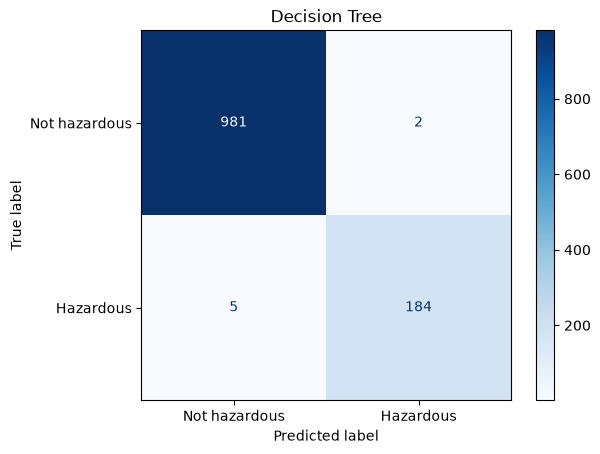

               precision    recall  f1-score   support

Not hazardous      0.995     0.998     0.996       983
    Hazardous      0.989     0.974     0.981       189

     accuracy                          0.994      1172
    macro avg      0.992     0.986     0.989      1172
 weighted avg      0.994     0.994     0.994      1172



In [9]:
dt_pred = dtree.predict(X_test)
print("Decision Tree accuracy: %.4f" % accuracy_score(y_test, dt_pred))
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues",
                                        display_labels=["Not hazardous", "Hazardous"])
plt.title("Decision Tree")
plt.show()
print(classification_report(y_test, dt_pred, target_names=["Not hazardous", "Hazardous"], digits=3))

Naive Bayes accuracy: 0.9539


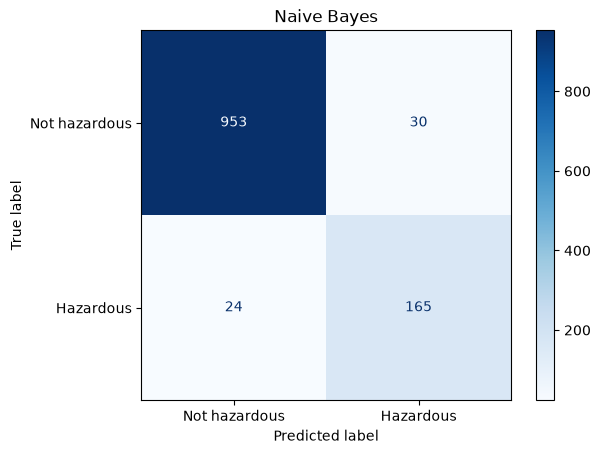

               precision    recall  f1-score   support

Not hazardous      0.975     0.969     0.972       983
    Hazardous      0.846     0.873     0.859       189

     accuracy                          0.954      1172
    macro avg      0.911     0.921     0.916      1172
 weighted avg      0.955     0.954     0.954      1172



In [10]:
nb_pred = nb_model.predict(X_test)
print("Naive Bayes accuracy: %.4f" % accuracy_score(y_test, nb_pred))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, cmap="Blues",
                                        display_labels=["Not hazardous", "Hazardous"])
plt.title("Naive Bayes")
plt.show()
print(classification_report(y_test, nb_pred, target_names=["Not hazardous", "Hazardous"], digits=3))

,Accuracy,Hazardous recall,Hazardous precision
Baseline (always 'not hazardous'),0.839,0.000,NaN
Decision Tree,0.994,0.974,0.989
Naive Bayes,0.954,0.873,0.846


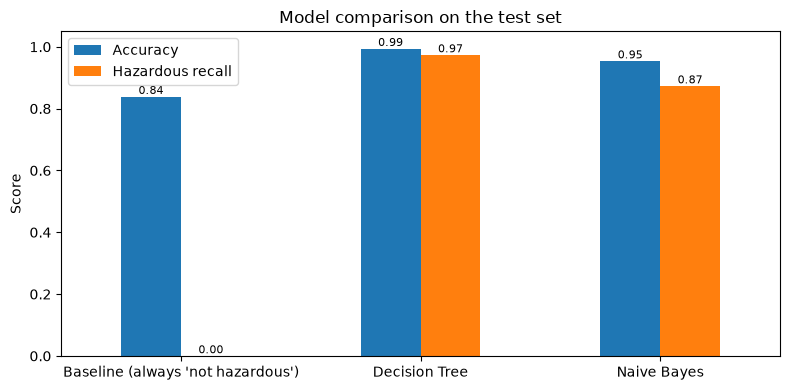

In [11]:
from sklearn.metrics import precision_score, recall_score

baseline = y_test.value_counts(normalize=True).max()
results = pd.DataFrame({
    "Accuracy": [baseline, accuracy_score(y_test, dt_pred), accuracy_score(y_test, nb_pred)],
    "Hazardous recall": [0.0, recall_score(y_test, dt_pred), recall_score(y_test, nb_pred)],
    "Hazardous precision": [np.nan, precision_score(y_test, dt_pred), precision_score(y_test, nb_pred)],
}, index=["Baseline (always 'not hazardous')", "Decision Tree", "Naive Bayes"])
display(results.round(3))

ax = results[["Accuracy", "Hazardous recall"]].plot(kind="bar", figsize=(8, 4), rot=0, ylim=(0, 1.05))
ax.set_title("Model comparison on the test set")
ax.set_ylabel("Score")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

## Step 5 - Findings

**Dataset:** NASA Asteroids Classification (`nasa.csv`, 4,687 asteroids × 40 columns). **Task:** predict `Hazardous` (True/False) with both a Decision Tree and Naive Bayes, and compare.

1. **Preprocessing / data reduction** - what did you have to clean, drop, encode, or sample, and why?

   The file had no missing values and was small enough that no sampling was needed. I dropped:
   - **Identifiers** (`Neo Reference ID`, `Name`), which carry no information about the asteroid.
   - **Date/bookkeeping columns** (`Close Approach Date`, `Orbit Determination Date`, `Epoch Date Close Approach`), which describe when data was recorded, not the asteroid's physics.
   - **Constant columns** (`Orbiting Body` is always Earth and `Equinox` is always J2000), which cannot help separate classes.
   - **Duplicate-unit columns.** Diameter appears in 8 versions (km/m/miles/feet × min/max), velocity in 3 units and miss distance in 4. They are perfectly correlated copies. Keeping them would mean Naive Bayes counts the same evidence several times (violating its independence assumption), so I kept one of each.

   That left 20 numeric features. The target was converted from True/False to 1/0. I used a stratified 75/25 split and applied **standard scaling** (fit on the training set only) because the features are on very different scales (e.g., diameter in km vs. orbital period in days).

2. **Data used** - which features did you select as predictors, and why those?

   All 20 remaining physical and orbital measurements: size (`Absolute Magnitude`, `Est Dia in KM(min)`), approach (`Relative Velocity km per sec`, `Miss Dist.(Astronomical)`), and orbit shape and position (`Minimum Orbit Intersection`, `Eccentricity`, `Semi Major Axis`, `Inclination`, `Perihelion Distance`, `Aphelion Dist`, `Orbital Period`, etc.). These describe how big the asteroid is and how close its orbit comes to Earth's, which is what "hazardous" is about. I kept them all instead of hand-picking, so the models could show which ones matter.

3. **Findings** - what did the analysis reveal about the data itself (patterns, surprises)?

   - The classes are imbalanced: only **16.1%** of asteroids are hazardous, so always guessing "not hazardous" already gives **83.9%** accuracy (the baseline).
   - The Decision Tree relied almost entirely on two features: **estimated diameter (importance 0.79)** and **Minimum Orbit Intersection (0.19)**. Everything else was close to 0.
   - That is not a coincidence. NASA *defines* a potentially hazardous asteroid as one whose minimum orbit intersection distance is ≤ 0.05 AU **and** whose absolute magnitude is ≤ 22 (roughly 140 m or larger). The tree essentially rediscovered NASA's labeling rule from the data. This explains the very high accuracy, and it means the target is a deterministic function of two columns rather than a fuzzy real-world outcome.
   - Many other features (velocity, miss distance on a single close approach, inclination) turned out to be nearly irrelevant to the label.

4. **Decision Tree vs Naive Bayes** - which performed better on your task, and what are the strengths and shortcomings of each one here?

   | Model | Accuracy | Hazardous precision | Hazardous recall |
   |---|---|---|---|
   | Baseline (always "not hazardous") | 0.839 | n/a | 0.000 |
   | **Decision Tree** (max_depth=5) | **0.994** | **0.989** | **0.974** |
   | Naive Bayes (Gaussian) | 0.954 | 0.846 | 0.873 |

   **The Decision Tree performed better** on every measure. Most importantly, it had higher **recall for the hazardous class** (97.4% vs. 87.3%): it missed only 5 of 189 hazardous asteroids, while Naive Bayes missed 24. A missed hazardous asteroid is the costly error, so recall matters most here.

   - *Decision Tree strengths:* it handles threshold rules ("diameter > X **and** MOID < Y") naturally, which is exactly how the label is defined. It is easy to interpret (we can read the splits and importances), and it doesn't care about feature scale. *Shortcomings:* it can overfit if allowed to grow deep (we limited it to depth 5), and small changes in the data can change the tree.
   - *Naive Bayes strengths:* very fast, simple, and still well above the baseline. *Shortcomings:* it assumes each feature is independent and normally distributed within each class. Here many orbital features are strongly related (e.g., semi-major axis, orbital period and mean motion are mathematically linked), and the label depends on a **combination** of two features (an AND rule), which a model that treats features independently cannot represent well. This produced more false alarms (lower precision) and more missed hazards (lower recall).

5. **Challenges** - What was difficult, and how did you handle it?

   - **Redundant columns:** the same measurement appeared in many units. I noticed this from `describe()`, where the columns had identical patterns, and kept one unit per quantity.
   - **Class imbalance:** accuracy alone was misleading because of the 83.9% baseline. I used a stratified split and reported precision and recall for the hazardous class alongside accuracy.
   - **Results that look too good:** 99.4% accuracy looked suspicious at first. Checking the feature importances and NASA's definition of "potentially hazardous" showed that the label is built from diameter and MOID. So the result is real, but the task is easier than a typical real-world prediction.
   - **Scaling:** to avoid data leakage, the scaler was fit on the training data only and then applied to the test data.

## Submission checklist

- This notebook (renamed `Last_First_Assignment7.ipynb`), with all cells run and output showing
- Link to your GitHub repository